Name : Bhalchim Roshani Ramchandra  
Roll No. : 08  
Title : Data Loading, Storage and File Formats  
Problem Statement: Analyzing Sales Data from Multiple File Formats  
Dataset: Sales data in multiple file formats (e.g., CSV, Excel, JSON)  
Description: The goal is to load and analyze sales data from different file formats, including CSV, Excel, and JSON, and perform data cleaning, transformation, and analysis on the
dataset.
Tasks to Perform:
Obtain sales data files in various formats, such as CSV, Excel, and JSON.
1. Load the sales data from each file format into the appropriate data structures or
dataframes.
2. Explore the structure and content of the loaded data, identifying any inconsistencies,
missing values, or data quality issues.
3. Perform data cleaning operations, such as handling missing values, removing
duplicates, or correcting inconsistencies.
4. Convert the data into a unified format, such as a common dataframe or data structure,
to enable seamless analysis.
5. Perform data transformation tasks, such as merging multiple datasets, splitting
columns, or deriving new variables.
6. Analyze the sales data by performing descriptive statistics, aggregating data by
specific variables, or calculating metrics such as total sales, average order value, or
product category distribution.
7. Create visualizations, such as bar plots, pie charts, or box plots, to represent the sales
data and gain insights into sales trends, customer behavior, or product performance.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("sales_data.csv")
df.to_excel("sales_data.xlsx", index=False)
df.to_json("sales_data.json", orient="records", indent=4)
print("Files created: sales_data.csv, sales_data.xlsx, sales_data.json")

Files created: sales_data.csv, sales_data.xlsx, sales_data.json


In [3]:
df_csv = pd.read_csv("sales_data.csv")
df_excel = pd.read_excel("sales_data.xlsx")
df_json = pd.read_json("sales_data.json")

print("CSV shape:", df_csv.shape)
print("Excel shape:", df_excel.shape)
print("JSON shape:", df_json.shape)
df_csv.head()

CSV shape: (25, 8)
Excel shape: (25, 8)
JSON shape: (25, 8)


,Order_ID,Order_Date,Product,Category,Quantity,Unit_Price,Customer,Region
0,101,2026-01-05,Laptop,Electronics,2.0,50000,Amit,West
1,102,2026-01-07,Mouse,Accessories,5.0,500,Priya,South
2,103,2026-01-09,Keyboard,Accessories,3.0,1500,Rahul,North
3,104,2026-01-12,Monitor,Electronics,1.0,12000,Sneha,East
4,105,2026-01-15,Laptop,Electronics,1.0,50000,Amit,West


In [4]:
df_csv.info()
print("\nMissing values:")
print(df_csv.isnull().sum())
print("\nDuplicate rows:", df_csv.duplicated().sum())
print("Category values:", df_csv["Category"].unique())

<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Order_ID    25 non-null     int64  
 1   Order_Date  25 non-null     str    
 2   Product     25 non-null     str    
 3   Category    25 non-null     str    
 4   Quantity    24 non-null     float64
 5   Unit_Price  25 non-null     int64  
 6   Customer    24 non-null     str    
 7   Region      25 non-null     str    
dtypes: float64(1), int64(2), str(5)
memory usage: 1.7 KB

Missing values:
Order_ID      0
Order_Date    0
Product       0
Category      0
Quantity      1
Unit_Price    0
Customer      1
Region        0
dtype: int64

Duplicate rows: 1
Category values: <StringArray>
['Electronics', 'Accessories', 'accessories', ' accessories ']
Length: 4, dtype: str


In [5]:
def clean(d):
    d = d.copy()
    d["Order_Date"] = pd.to_datetime(d["Order_Date"])
    d["Category"] = d["Category"].str.strip().str.title()
    d["Quantity"] = d["Quantity"].fillna(d["Quantity"].median())
    d["Customer"] = d["Customer"].fillna("Unknown")
    return d.drop_duplicates()

clean_csv = clean(df_csv)
clean_excel = clean(df_excel)
clean_json = clean(df_json)

print("Missing values after cleaning:", clean_csv.isnull().sum().sum())
print("Category values after cleaning:", clean_csv["Category"].unique())
print("Shape after removing duplicates:", clean_csv.shape)

Missing values after cleaning: 0
Category values after cleaning: <StringArray>
['Electronics', 'Accessories']
Length: 2, dtype: str
Shape after removing duplicates: (24, 8)


In [6]:
combined = pd.concat([clean_csv, clean_excel, clean_json], ignore_index=True)
print("Shape after combining:", combined.shape)

sales = combined.drop_duplicates().reset_index(drop=True)
print("Unified shape (duplicates removed):", sales.shape)

Shape after combining: (72, 8)
Unified shape (duplicates removed): (24, 8)


In [7]:
sales["Year"] = sales["Order_Date"].dt.year
sales["Month"] = sales["Order_Date"].dt.month_name()
sales["Total_Sales"] = sales["Quantity"] * sales["Unit_Price"]

managers = pd.DataFrame({
    "Region": ["North", "South", "East", "West"],
    "Region_Manager": ["Amit Sharma", "Priya Patil", "Rahul Verma", "Sneha Joshi"]
})
sales = sales.merge(managers, on="Region", how="left")
sales.head()

,Order_ID,Order_Date,Product,Category,Quantity,Unit_Price,Customer,Region,Year,Month,Total_Sales,Region_Manager
0,101,2026-01-05,Laptop,Electronics,2.0,50000,Amit,West,2026,January,100000.0,Sneha Joshi
1,102,2026-01-07,Mouse,Accessories,5.0,500,Priya,South,2026,January,2500.0,Priya Patil
2,103,2026-01-09,Keyboard,Accessories,3.0,1500,Rahul,North,2026,January,4500.0,Amit Sharma
3,104,2026-01-12,Monitor,Electronics,1.0,12000,Sneha,East,2026,January,12000.0,Rahul Verma
4,105,2026-01-15,Laptop,Electronics,1.0,50000,Amit,West,2026,January,50000.0,Sneha Joshi


In [8]:
print("Total sales:", sales["Total_Sales"].sum())
print("Average order value:", round(sales["Total_Sales"].mean(), 2))
print("Total orders:", sales["Order_ID"].nunique())

print("\nSales by category:")
print(sales.groupby("Category")["Total_Sales"].sum())
print("\nSales by product:")
print(sales.groupby("Product")["Total_Sales"].sum())
print("\nSales by region:")
print(sales.groupby("Region")["Total_Sales"].sum())

sales[["Quantity", "Unit_Price", "Total_Sales"]].describe()

Total sales: 502000.0
Average order value: 20916.67
Total orders: 24

Sales by category:
Category
Accessories     56000.0
Electronics    446000.0
Name: Total_Sales, dtype: float64

Sales by product:
Product
Headphones     26000.0
Keyboard       18000.0
Laptop        350000.0
Monitor        96000.0
Mouse          12000.0
Name: Total_Sales, dtype: float64

Sales by region:
Region
East      99000.0
North    140500.0
South     77500.0
West     185000.0
Name: Total_Sales, dtype: float64


,Quantity,Unit_Price,Total_Sales
count,24.000000,24.000000,24.000000
mean,2.666667,13666.666667,20916.666667
std,1.403928,19522.376608,28956.363972
min,1.000000,500.000000,2000.000000
25%,2.000000,1500.000000,3000.000000
50%,2.000000,2000.000000,6000.000000
75%,3.250000,12000.000000,24000.000000
max,6.000000,50000.000000,100000.000000


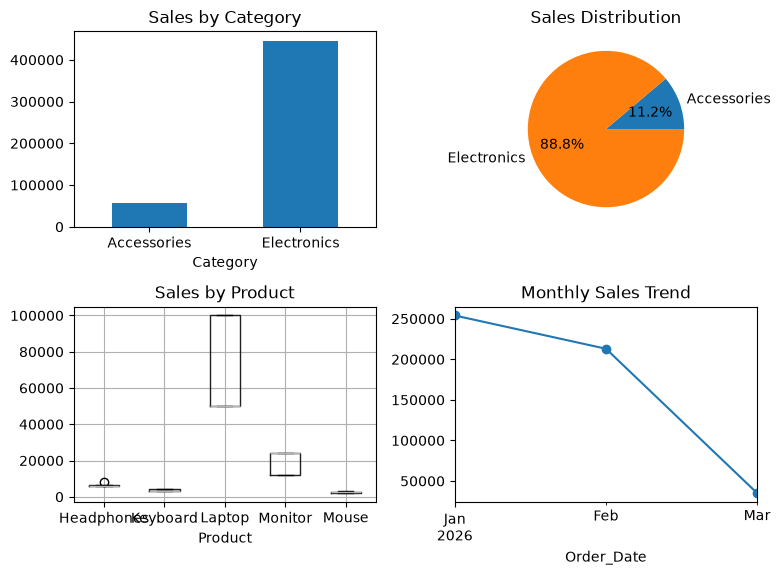

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(8, 6))

sales.groupby("Category")["Total_Sales"].sum().plot(kind="bar", ax=axes[0, 0], rot=0)
axes[0, 0].set_title("Sales by Category")

sales.groupby("Category")["Total_Sales"].sum().plot(kind="pie", autopct="%1.1f%%", ax=axes[0, 1])
axes[0, 1].set_title("Sales Distribution")
axes[0, 1].set_ylabel("")

sales.boxplot(column="Total_Sales", by="Product", ax=axes[1, 0])
axes[1, 0].set_title("Sales by Product")

monthly = sales.groupby(sales["Order_Date"].dt.to_period("M"))["Total_Sales"].sum()
monthly.plot(kind="line", marker="o", ax=axes[1, 1])
axes[1, 1].set_title("Monthly Sales Trend")

plt.suptitle("")
plt.tight_layout()
plt.show()